# 09 — Is difficulty a property of the series, or of the week?

Notebooks 05–08 took Chronos-2 as far as this problem seems to allow: context length swept and chosen per
horizon segment, the two winners stitched, a LoRA fine-tune on top. Covariates lost, cross-learning lost,
every encoding of the blank periods lost. One lever is left — **treat different series differently**:
fine-tune per group, cross-learn inside a group, one model per group.

That lever has a precondition, and it is testable before building anything. For a static grouping to help,
**difficulty has to be a stable property of a series**. If the items that are hard to forecast this week are
not the ones that were hard last week, then no grouping — hand-made, clustered or learned — has anything to
hold on to. That is a ceiling argument, and it costs a handful of extra forecast runs rather than a month of
clustering.

**Method.** Forecast from 24 origins, one week apart, and study the error of each (series, origin) pair.
Decompose it:

$$x_{f,o} = \mu + \alpha_f + \beta_o + \varepsilon_{f,o}$$

$\alpha_f$ is the series — by construction the only part a static grouping could exploit. $\beta_o$ is the
week: some weeks are hard for everyone. $\varepsilon_{f,o}$ is everything left, and it gets split further
into a part that survives to the next origin (persistent), a part that does not (transient), and the
measurement noise of the cell itself, read off the odd and even days of each window.

**Decision rule, fixed before looking.** Median Spearman between consecutive origins $\geq 0.6$ *and* at
least 35% of the variance on the series → difficulty is persistent, a grouping has something real. Spearman
$\leq 0.3$ *or* under 20% on the series → it is not, and no static grouping can help. Anything between →
partial, weigh it against the complexity. The rule lives in `persistence.verdict` so it cannot be read
wishfully after the fact.

**Added after the first run, and kept separate from the rule above.** The Spearman arm of
that rule is applied to a ranking of *measured* 7-day errors, and section 2 shows those
cells carry a large share of sampling noise. A rank correlation between two noisy
measurements is attenuated by the noise in both, so the 0.6 bar is a bar on an attenuated
quantity -- a specification error that was identifiable before seeing any data, and one
the threshold's source had no reason to share, having been set for windows of a different
reliability. The rule is left exactly as written and its verdict is reported as it stands;
section 3b reports the quantity the rule was *trying* to bound, derived from the same
decomposition.

**Three choices that make the measurement honest**, all argued in the module docstring: the **zero-shot**
model only (the stitched best model involves a checkpoint fine-tuned on history up to the test origin —
walking it backwards would let it see the future of every earlier window); origins counted back from the
**validation** origin, so the test window is never read; **non-overlapping** scored windows, so the lag-1
autocovariance is not an artefact of overlap.

In [1]:
%load_ext autoreload
%autoreload 2

import json

import numpy as np
import polars as pl
import matplotlib.pyplot as plt

from m5_chronos2.data import ARTIFACTS_DIR, roster_name
from m5_chronos2.evaluation import actuals, make_windows
from m5_chronos2.chronos2 import experiment_path, history, resolve_device
from m5_chronos2.persistence import (
    N_ORIGINS, SEGMENT_DAYS,
    bootstrap_shares, build_panel, cell_wql, decompose, origin_grid, rank_agreement,
    scored_cells, simulate_panel, spearman, transient_ratio, verdict,
)
from m5_chronos2.plots import (
    GRID_COLOR, MAIN_COLOR, MUTED_TEXT_COLOR, TEXT_COLOR, plot_fan, use_blog_style,
)

use_blog_style()

## Settings

In [2]:
SAMPLE_SIZE = 500
SEED = 42
NAME = roster_name(SAMPLE_SIZE, SEED)

# The context length notebook 07 chose for days 1-7 — the segment this 7-day sweep scores.
choice = json.loads((ARTIFACTS_DIR / f"context_choice_{NAME}.json").read_text())
CONTEXT = int(choice["early_context"])

N_BOOTSTRAP = 1000     # resamples of the series, for the confidence intervals
WORST_DECILE = 0.10    # "the hardest tenth of series": does it survive to the next origin?

print(f"{N_ORIGINS} origins, {SEGMENT_DAYS} days apart, vanilla Chronos-2 at context {CONTEXT}")

24 origins, 7 days apart, vanilla Chronos-2 at context 1099


In [3]:
sales = pl.read_parquet(ARTIFACTS_DIR / f"sales_flags_{NAME}.parquet")
truth = actuals(sales)
VALIDATION_ORIGIN = make_windows().filter(pl.col("role") == "validation")["origin"][0]

ORIGINS = origin_grid(VALIDATION_ORIGIN, N_ORIGINS, SEGMENT_DAYS)
print(f"origins from {ORIGINS[0]} to {ORIGINS[-1]}")

# Every origin needs at least CONTEXT days of history behind it, or the earliest ones are
# quietly forecasting from less than the later ones and the panel is not comparable.
earliest_day = sales["date"].min()
room = (ORIGINS[0] - earliest_day).days
print(f"history available at the earliest origin: {room} days (context asks for {CONTEXT})")
assert room >= CONTEXT, "the earliest origin has less history than the context length"

origins from 2015-10-18 to 2016-03-27
history available at the earliest origin: 1723 days (context asks for 1099)


## 0. Does the estimator work at all?

Before the real data, the positive control — the step most of these analyses skip, and the one that decides
whether a negative result means anything. `simulate_panel` builds a panel from known components at this
panel's size and noise level; the decomposition has to recover them.

This also exposes the one limit of the method worth knowing about: a difficulty that *drifts slowly* is
partly indistinguishable from a constant one over a panel of finite span, so it is shared between the series
term and the persistent term. Their **sum** is what is identified, and that is why `shares()` also reports
`stable`.

In [4]:
control, planted = simulate_panel(n_series=250, n_origins=N_ORIGINS, seed=SEED)
control_result = decompose(control)
recovered = control_result.shares()

components = ["series", "origin", "persistent", "transient", "noise"]
control_table = pl.DataFrame({
    "component": components,
    "planted": [planted[c] for c in components],
    "recovered": [recovered["series_adjusted" if c == "series" else c] for c in components],
}).with_columns(
    (100 * pl.col("planted")).round(1).alias("planted %"),
    (100 * pl.col("recovered")).round(1).alias("recovered %"),
).drop("planted", "recovered")
print(f"raw (unadjusted) series share: {100 * recovered['series']:.1f}% — inflated by the noise in each alpha_f")
control_table

raw (unadjusted) series share: 18.4% — inflated by the noise in each alpha_f


component,planted %,recovered %
str,f64,f64
"""series""",12.9,15.2
"""origin""",3.7,5.2
"""persistent""",8.3,5.9
"""transient""",58.9,57.3
"""noise""",13.2,13.2


In [5]:
# Where does a slow drift land? Sweep its autocorrelation, holding the planted amount fixed.
rows = []
for rho in [0.0, 0.3, 0.6, 0.85, 0.97]:
    simulated, truth_shares = simulate_panel(n_series=250, sd_series=0.0, sd_persistent=0.35,
                                             rho=rho, seed=SEED + 1)
    got = decompose(simulated).shares()
    rows.append({"rho": rho, "planted drift %": 100 * truth_shares["persistent"],
                 "-> series %": 100 * got["series_adjusted"], "-> persistent %": 100 * got["persistent"],
                 "sum %": 100 * got["stable"]})
pl.DataFrame(rows).with_columns(
    [pl.col(name).round(1) for name in ["planted drift %", "-> series %", "-> persistent %", "sum %"]]
)

rho,planted drift %,-> series %,-> persistent %,sum %
f64,f64,f64,f64,f64
0.0,0.0,0.7,0.0,0.7
0.3,6.3,1.6,3.3,4.8
0.6,12.6,3.6,7.3,10.9
0.85,18.3,8.8,7.0,15.8
0.97,20.1,15.9,2.0,18.0


The split moves with the timescale; the sum does not. Two readings follow, and both are used below: the
**series** share answers "could a grouping fitted once and left alone help", the **sum** answers "is there
anything stable at all, even if it has to be refitted".

Two more controls, run silently: a panel with no series effect, where the bias adjustment has to return 0;
and a white-noise panel, where the persistence correction has to return 0 rather than the negative value
double-centring induces.

In [6]:
flat, _ = simulate_panel(n_series=250, sd_series=0.0, sd_persistent=0.0, seed=SEED + 2)
flat_shares = decompose(flat).shares()
print(f"no series effect, no drift:  raw series {100 * flat_shares['series']:.2f}%"
      f"  ->  adjusted {100 * flat_shares['series_adjusted']:.2f}%"
      f"  |  persistent {100 * flat_shares['persistent']:+.2f}%   (both truths: 0%)")

white, _ = simulate_panel(n_series=400, sd_series=0.0, sd_origin=0.0, sd_persistent=0.0, seed=SEED + 3)
white_result = decompose(white)
from m5_chronos2.persistence import _lag1_autocovariance
print(f"white noise only:  raw lag-1 autocovariance {_lag1_autocovariance(white_result.eps):+.5f}"
      f"  ->  corrected {white_result.v_persistent:+.5f}   (truth: 0)")

no series effect, no drift:  raw series 4.47%  ->  adjusted 0.81%  |  persistent +0.31%   (both truths: 0%)
white noise only:  raw lag-1 autocovariance -0.01286  ->  corrected +0.00458   (truth: 0)


## 1. The panel

24 forecasts, read back from `artifacts/experiments/`. They are produced by the `origin_sweep` stage on the
tower (`uv run python scripts/run_stage.py --stages origin_sweep`); this notebook computes nothing.

In [7]:
paths = [experiment_path(f"origin_sweep_ctx{CONTEXT}_origin{origin}", NAME) for origin in ORIGINS]
missing = [path.name for path in paths if not path.exists()]
if missing:
    raise FileNotFoundError(
        f"{len(missing)} forecast(s) missing, starting with {missing[0]}.\n"
        "Run:  uv run python scripts/run_stage.py --stages origin_sweep   (on the tower), then rsync back."
    )

sweep = pl.concat([pl.read_parquet(path) for path in paths])
print(f"{sweep.height:,} forecast rows over {sweep['origin'].n_unique()} origins")

335,860 forecast rows over 24 origins


In [8]:
# The scoring conditions of notebook 03, applied to a 7-day window instead of 28.
cells = scored_cells(sales, ORIGINS)
errors = cell_wql(sweep, truth, cells)
panel = build_panel(errors)

n_series, n_origins = panel.shape
print(f"scorable pairs: {cells.height:,}  ->  balanced panel: {n_series} series x {n_origins} origins")
print(f"  {panel.dropped['series_seen']} series appear at least once; "
      f"{panel.dropped['series_kept']} are scorable at every origin")
print(f"  cells with an undefined WQL (no sales in the window): {panel.dropped['cells_with_zero_wql']:,}")
assert n_series >= 80, "panel too thin to carry a conclusion — widen the roster before reading on"

scorable pairs: 9,187  ->  balanced panel: 138 series x 24 origins
  494 series appear at least once; 138 are scorable at every origin
  cells with an undefined WQL (no sales in the window): 0


The balanced panel is the honest object: double-centring a grid with holes is a different estimator, and a
series missing from half the origins would have its $\alpha_f$ measured on a different set of weeks than its
neighbours'. The count dropped by the balance requirement is printed above rather than buried, because a
filter that quietly removes most of the roster changes the question being answered.

Here is the panel itself — rows are series, sorted by their average difficulty, columns are origins in time
order. A world in which difficulty is a property of the series looks like clean horizontal bands.

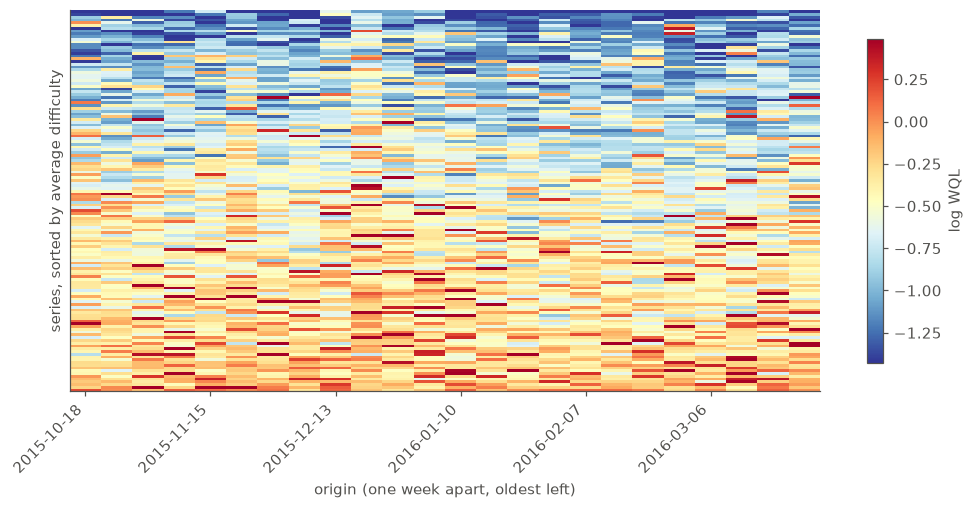

In [9]:
def plot_panel(panel, result):
    order = np.argsort(result.alpha)
    fig, ax = plt.subplots(figsize=(11, 4.5))
    image = ax.imshow(panel.x[order], aspect="auto", cmap="RdYlBu_r", interpolation="nearest",
                      vmin=np.quantile(panel.x, 0.02), vmax=np.quantile(panel.x, 0.98))
    ax.set_xlabel("origin (one week apart, oldest left)")
    ax.set_ylabel("series, sorted by average difficulty")
    ax.set_xticks(range(0, panel.shape[1], 4))
    ax.set_xticklabels([str(panel.origins[i]) for i in range(0, panel.shape[1], 4)], rotation=45, ha="right")
    ax.set_yticks([])
    ax.grid(False)
    fig.colorbar(image, ax=ax, label="log WQL", shrink=0.85)
    return fig

result = decompose(panel)
plot_panel(panel, result)
plt.show()

## 2. Where the error lives

The variance budget, with confidence intervals from resampling **series** (not cells: the question is
whether another sample of items would give the same answer, and cells within a series are not independent —
that dependence is the thing being measured).

In [10]:
intervals = bootstrap_shares(panel, n_draws=N_BOOTSTRAP, seed=SEED)
shares = result.shares()

budget = pl.DataFrame([
    {"component": name,
     "share %": 100 * shares[key],
     "CI low %": 100 * intervals[key][0],
     "CI high %": 100 * intervals[key][1]}
    for name, key in [
        ("series (raw)", "series"),
        ("series (bias-adjusted)", "series_adjusted"),
        ("origin", "origin"),
        ("series x origin", "interaction"),
        ("  — persistent", "persistent"),
        ("  — transient", "transient"),
        ("  — sampling noise", "noise"),
        ("stable (series + persistent)", "stable"),
    ]
]).with_columns(
    [pl.col(name).round(1) for name in ["share %", "CI low %", "CI high %"]]
)
print(f"noise floor measured on {result.n_noise_cells:,} of {n_series * n_origins:,} cells "
      f"(both halves of the window need a sale)")
budget

noise floor measured on 2,989 of 3,312 cells (both halves of the window need a sale)


component,share %,CI low %,CI high %
str,f64,f64,f64
"""series (raw)""",43.9,38.1,49.6
"""series (bias-adjusted)""",41.7,35.6,47.6
"""origin""",2.0,1.6,3.3
"""series x origin""",54.1,48.4,59.6
""" — persistent""",4.0,2.0,5.9
""" — transient""",7.5,1.4,12.3
""" — sampling noise""",42.6,37.4,48.9
"""stable (series + persistent)""",45.7,39.4,51.1


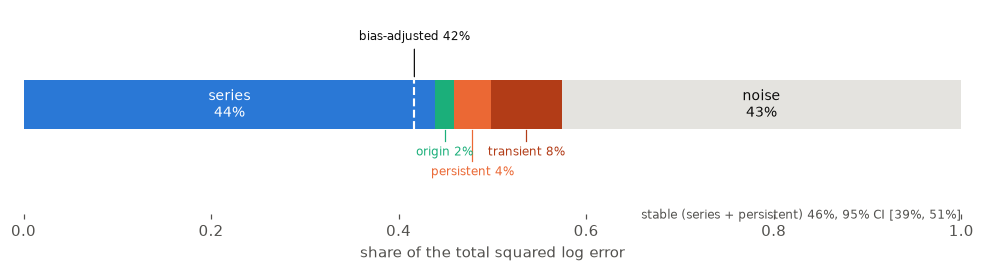

In [11]:
def plot_budget(shares, intervals):
    """The budget as it balances: the raw components sum to 1 exactly.

    The bias-adjusted series share is drawn as a mark *inside* the series block rather
    than substituted for it. Substituting would leave the five numbers short of 100%,
    and renormalising them would spread the adjustment over the noise term, which did
    not cause it.
    """
    parts = [("series", "series", MAIN_COLOR),
             ("origin", "origin", "#1baf7a"),
             ("persistent", "persistent", "#eb6834"),
             ("transient", "transient", "#b23c17"),
             ("noise", "noise", GRID_COLOR)]
    values = [shares[key] for _, key, _ in parts]
    assert abs(sum(values) - 1) < 1e-9, f"the budget does not balance: {sum(values):.4f}"

    fig, ax = plt.subplots(figsize=(11, 2.4))
    left, below = 0.0, []
    for (label, _, color), value in zip(parts, values):
        ax.barh(0, value, left=left, color=color, height=0.5)
        if value >= 0.10:
            ax.text(left + value / 2, 0, f"{label}\n{100 * value:.0f}%", ha="center", va="center",
                    color="white" if color != GRID_COLOR else TEXT_COLOR, fontsize=9)
        else:
            below.append((left + value / 2, label, value, color))
        left += value

    # Narrow blocks get their label under the bar, with a leader, so they never overlap.
    for position, (centre, label, value, color) in enumerate(below):
        offset = -0.42 - 0.20 * (position % 2)
        ax.plot([centre, centre], [-0.26, offset + 0.05], color=color, linewidth=0.8)
        ax.text(centre, offset, f"{label} {100 * value:.0f}%", ha="center", va="top",
                color=color, fontsize=8)

    # Where the series block ends once the noise in each alpha_f is taken out of it.
    adjusted = shares["series_adjusted"]
    ax.plot([adjusted, adjusted], [-0.25, 0.25], color="white", linestyle="--", linewidth=1.4)
    ax.annotate(f"bias-adjusted {100 * adjusted:.0f}%", xy=(adjusted, 0.25),
                xytext=(adjusted, 0.62), ha="center", va="bottom", fontsize=8, color=TEXT_COLOR,
                arrowprops=dict(arrowstyle="-", color=TEXT_COLOR, linewidth=0.8))

    low, high = intervals["stable"]
    ax.text(1.0, -1.05, f"stable (series + persistent) {100 * shares['stable']:.0f}%, "
                        f"95% CI [{100 * low:.0f}%, {100 * high:.0f}%]",
            ha="right", va="top", fontsize=8, color=MUTED_TEXT_COLOR)

    ax.set_xlim(0, 1)
    ax.set_ylim(-1.1, 0.95)
    ax.set_yticks([])
    ax.set_xlabel("share of the total squared log error")
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    return fig

plot_budget(shares, intervals)
plt.show()

## 3. The same question, without a variance model

A decomposition is a model and can be wrong. Rank agreement is not: order the series by error at one origin,
order them again at the next, and ask whether the two orderings agree. If this disagrees with section 2,
something above is broken. If it *agrees* -- and section 3b shows it agrees to two decimal places -- then the
two instruments are measuring the same thing and the model has earned some trust.

In [12]:
ranks = rank_agreement(panel, decile=WORST_DECILE)
print(f"median Spearman between consecutive origins : {ranks['consecutive_median']:+.2f}")
print(f"Spearman, first origin vs last              : {ranks['first_vs_last']:+.2f}")
print(f"hardest {WORST_DECILE:.0%} still hardest next origin   : {100 * ranks['worst_decile_survival']:.0f}%"
      f"   (a coin flip would give {100 * ranks['worst_decile_random']:.0f}%)")

median Spearman between consecutive origins : +0.52
Spearman, first origin vs last              : +0.41
hardest 10% still hardest next origin   : 16%   (a coin flip would give 10%)


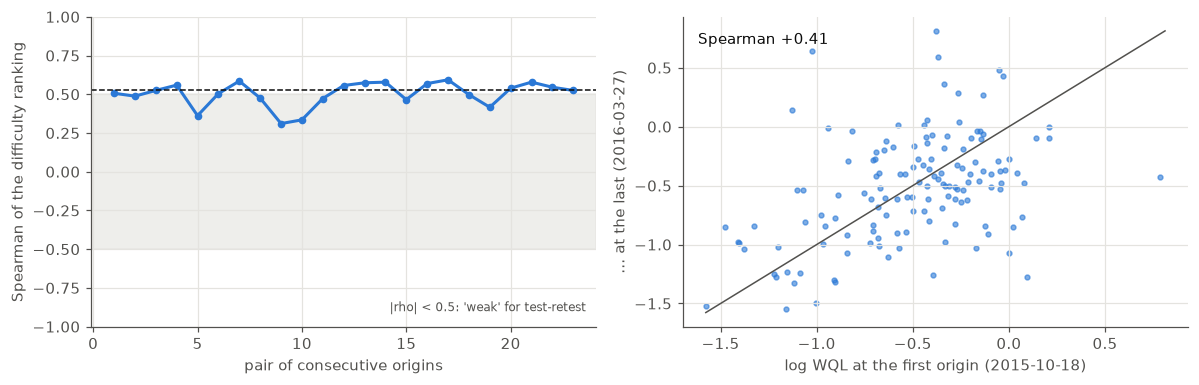

In [13]:
def plot_ranks(panel, ranks):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

    ax = axes[0]
    values = ranks["consecutive"]
    ax.plot(range(1, len(values) + 1), values, color=MAIN_COLOR, marker="o", markersize=4)
    ax.axhline(ranks["consecutive_median"], color=TEXT_COLOR, linestyle="--", linewidth=1)
    ax.axhspan(-0.5, 0.5, color=GRID_COLOR, alpha=0.6, zorder=0)
    ax.text(0.98, 0.04, "|rho| < 0.5: 'weak' for test-retest", transform=ax.transAxes,
            ha="right", va="bottom", color=MUTED_TEXT_COLOR, fontsize=8)
    ax.set_ylim(-1, 1)
    ax.set_xlabel("pair of consecutive origins")
    ax.set_ylabel("Spearman of the difficulty ranking")

    ax = axes[1]
    first, last = panel.x[:, 0], panel.x[:, -1]
    ax.scatter(first, last, s=10, color=MAIN_COLOR, alpha=0.6)
    limits = [min(first.min(), last.min()), max(first.max(), last.max())]
    ax.plot(limits, limits, color=MUTED_TEXT_COLOR, linewidth=1)
    ax.set_xlabel(f"log WQL at the first origin ({panel.origins[0]})")
    ax.set_ylabel(f"... at the last ({panel.origins[-1]})")
    ax.text(0.03, 0.95, f"Spearman {ranks['first_vs_last']:+.2f}", transform=ax.transAxes,
            va="top", color=TEXT_COLOR)
    fig.tight_layout()
    return fig

plot_ranks(panel, ranks)
plt.show()

## 3b. The two sections measure the same thing

Sections 2 and 3 are not independent readings to be weighed against each other: the
decomposition **predicts** the rank correlation, and the prediction can be written down from
the variance shares alone.

Within one origin the week effect `beta_o` is a constant and does not touch the across-series
ranking, so at a single origin the spread of the measured error is
`var(alpha) + v_persistent + v_transient + v_noise`, while the covariance between two
consecutive origins keeps only the parts that survive the step:
`var(alpha) + v_persistent`. Their ratio is the correlation the decomposition expects to
observe. Six months apart `v_persistent` has decayed, and only `var(alpha)` remains.

Dividing instead by the *reliable* part of a cell -- everything except the sampling noise --
gives the correlation between the underlying difficulties rather than between their noisy
estimates. That is the quantity the decision rule was reaching for.

In [14]:
shares_for_rho = result.shares()
v_alpha = shares_for_rho["series_adjusted"]
v_pers = shares_for_rho["persistent"]
v_trans = shares_for_rho["transient"]
v_noise = shares_for_rho["noise"]

cell_variance = v_alpha + v_pers + v_trans + v_noise
reliability = (v_alpha + v_pers + v_trans) / cell_variance

rho = pl.DataFrame([
    {"quantity": "consecutive origins", "predicted": (v_alpha + v_pers) / cell_variance,
     "observed": ranks["consecutive_median"],
     "noise-corrected": (v_alpha + v_pers) / (v_alpha + v_pers + v_trans)},
    {"quantity": "first vs last origin", "predicted": v_alpha / cell_variance,
     "observed": ranks["first_vs_last"],
     "noise-corrected": v_alpha / (v_alpha + v_pers + v_trans)},
]).with_columns([pl.col(c).round(3) for c in ("predicted", "observed", "noise-corrected")])

print(f"reliability of one 7-day cell: {reliability:.3f}"
      f"   ({100 * v_noise / cell_variance:.0f}% of its variance is sampling noise)")
assert abs(rho["predicted"][0] - rho["observed"][0]) < 0.08, \
    "the decomposition and the rank statistic disagree: one of them is wrong"
rho

reliability of one 7-day cell: 0.555   (44% of its variance is sampling noise)


quantity,predicted,observed,noise-corrected
str,f64,f64,f64
"""consecutive origins""",0.477,0.525,0.859
"""first vs last origin""",0.435,0.406,0.784


**The predicted and observed columns agree to within a few hundredths, on both rows.** Two
instruments built on different assumptions -- a variance model and a distribution-free rank
statistic -- return the same number, which is the strongest internal check this notebook has.

And the third column is the answer to the question the rule asked. A single 7-day window is
only about 55% reliable, because an item selling a few units a week carries that much
counting noise; seen through it, a difficulty ordering that is stable at **0.86** between
consecutive origins can only appear as 0.52. The observed 0.52 was never evidence of weak
stability. It was evidence of a noisy ruler.

## 4. Validating the residual of the residual

`transient` is a difference of differences: it is whatever is left after subtracting noise and persistence
from the interaction, so *any* leak — a broken origin, a series going dark, a join artefact — lands in it.
Before believing a large transient share, look at the cells it is built from.

For each cell, predict its residual from the neighbouring origins using the autocovariances already
estimated (nothing new is fitted) and square what is left, in units of the noise floor. A large ratio should
be one origin jumping off an otherwise flat trace, **with a visible event underneath**. If instead the
extreme cells are near-zero-volume series, the transient share is measuring data holes and the ceiling
argument has to be re-run on a cleaner panel.

In [15]:
ratio = transient_ratio(panel, result)
worst = np.unravel_index(np.argmax(ratio), ratio.shape)
calm = np.unravel_index(np.argmin(ratio), ratio.shape)
print(f"largest t_ratio {ratio[worst]:,.0f}  — {panel.ids[worst[0]]} at {panel.origins[worst[1]]}")
print(f"smallest        {ratio[calm]:.2f}  — {panel.ids[calm[0]]} at {panel.origins[calm[1]]}")
print(f"median {np.median(ratio):.2f}; share of cells above 10x the noise floor: {100 * (ratio > 10).mean():.1f}%")

largest t_ratio 59  — HOUSEHOLD_1_410_CA_4_evaluation at 2015-11-29
smallest        0.00  — FOODS_3_103_CA_1_evaluation at 2016-02-07
median 0.39; share of cells above 10x the noise floor: 1.8%


/var/folders/k4/pclq47c50r78wfcdxrrbr27c0000gn/T/ipykernel_39015/728640508.py:23: DeprecationWarning: `is_in` with a collection of the same datatype is ambiguous and deprecated.
Please use `implode` to return to previous behavior.

See https://github.com/pola-rs/polars/issues/22149 for more information.
  actual = truth.filter((pl.col("id") == series_id)


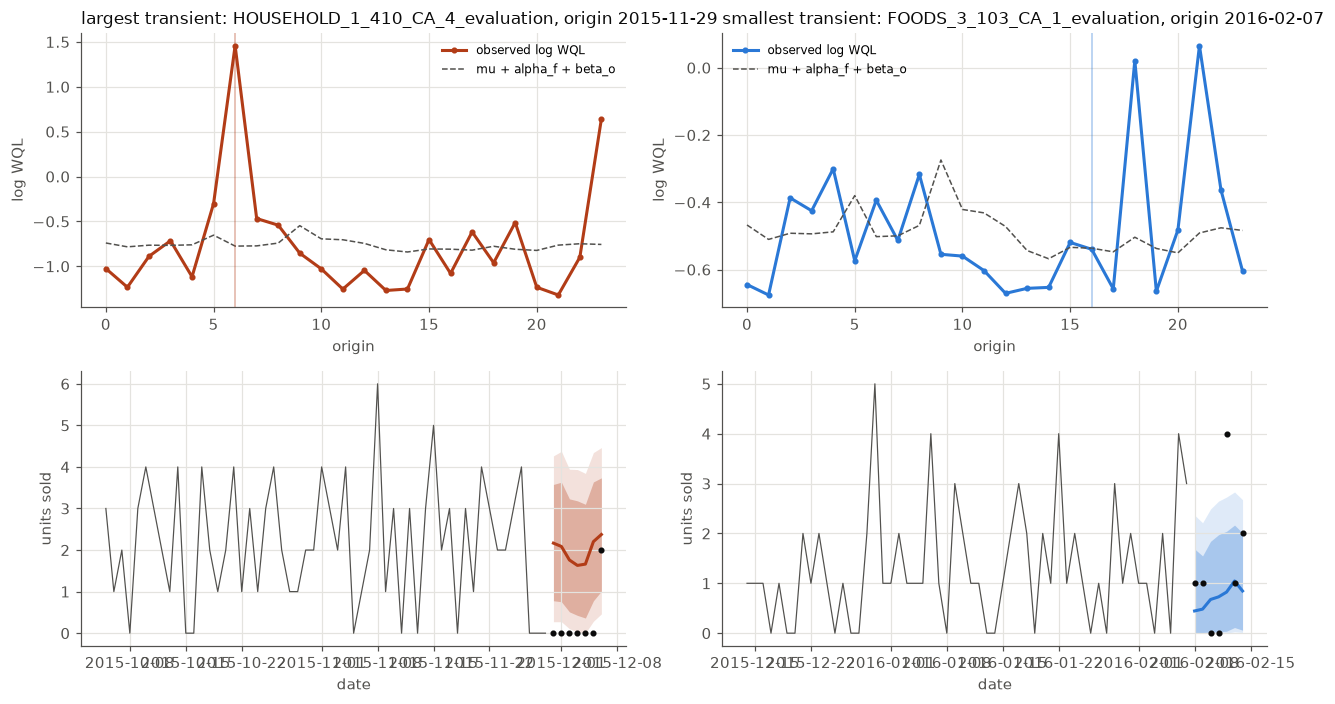

In [16]:
def plot_cell(axes, panel, result, cell, color, label):
    series_index, origin_index = cell
    series_id, origin = panel.ids[series_index], panel.origins[origin_index]

    # Top: this series' error across every origin, against what the model of section 2 expects of it.
    ax = axes[0]
    expected = result.mu + result.alpha[series_index] + result.beta
    ax.plot(range(panel.shape[1]), panel.x[series_index], color=color, marker="o", markersize=3,
            label="observed log WQL")
    ax.plot(range(panel.shape[1]), expected, color=MUTED_TEXT_COLOR, linestyle="--", linewidth=1,
            label="mu + alpha_f + beta_o")
    ax.axvline(origin_index, color=color, linewidth=1, alpha=0.4)
    ax.set_title(f"{label}: {series_id}, origin {origin}", loc="left")
    ax.set_xlabel("origin")
    ax.set_ylabel("log WQL")
    ax.legend(fontsize=8, loc="best")

    # Bottom: what actually happened that week.
    past = (history(sales, origin, [series_id])
            .select("date", pl.col("sales").alias("y")).tail(8 * SEGMENT_DAYS))
    window = sweep.filter((pl.col("id") == series_id) & (pl.col("origin") == origin)).sort("date")
    window = window.filter((pl.col("date") - pl.col("origin")).dt.total_days() <= SEGMENT_DAYS)
    actual = truth.filter((pl.col("id") == series_id)
                          & pl.col("date").is_in(window["date"])).sort("date")
    plot_fan(axes[1], past, window, actual, color=color, label="forecast")
    axes[1].set_xlabel("date")

fig, axes = plt.subplots(2, 2, figsize=(12, 6.5))
plot_cell(axes[:, 0], panel, result, worst, "#b23c17", "largest transient")
plot_cell(axes[:, 1], panel, result, calm, MAIN_COLOR, "smallest transient")
fig.tight_layout()
plt.show()

## 5. Is the stable part anything more than volume?

A large series share is not the end of the argument, it is the start of one. WQL is
scale-free — it divides by the total actual — so a dependence on volume would not be an
artefact of units. It would be a statement about **predictability**: an item selling
0.3 units a day has an irreducibly high relative error, and that is a permanent
property of the item.

That distinction decides what $\alpha_f$ is worth. If it is a function of volume, then
"group the series by difficulty" means "bucket them by volume" — which needs no
clustering, and which Chronos-2 already reads off the history by itself. If something
survives after volume is taken out, there is a real grouping question, and notebook 10
is where it gets asked.

**One correction is mandatory here and it is easy to miss.** The measurement noise of a
7-day window is itself strongly volume-dependent: a window selling three units carries
far more sampling noise than one selling three hundred. Since $\alpha_f$ is a mean of
noisy cells, low-volume series have their $\alpha$ inflated *more* — which would
manufacture exactly the volume relationship being tested for. The global bias
adjustment of section 2 cannot fix a bias that differs per series, so this section uses
each series' own noise floor, measured from its own odd/even halves.

The covariates are computed on the history **before the first origin**, so they are a
prior property of the item rather than a summary of the windows being scored.

In [17]:
from m5_chronos2.persistence import explain_alpha, series_noise

prior = sales.filter((pl.col("date") <= ORIGINS[0]) & ~pl.col("is_missing"))
profile = prior.group_by("id").agg(
    pl.col("sales").mean().alias("mean_daily"),
    (pl.col("sales") == 0).mean().alias("zero_share"),
    pl.len().alias("history_days"),
)
# Reindex onto the panel's own row order: alpha[i] belongs to panel.ids[i].
profile = pl.DataFrame({"id": panel.ids}).join(profile, on="id", how="left")
assert profile["mean_daily"].null_count() == 0, "a panel series has no history before the first origin"

log_volume = np.log(np.maximum(profile["mean_daily"].to_numpy(), 1e-3))
zero_share = profile["zero_share"].to_numpy()
print(f"median {np.exp(np.median(log_volume)):.2f} units/day; "
      f"median share of zero-sale days {100 * np.median(zero_share):.0f}%")

explained = explain_alpha(panel, result, {"log volume": log_volume, "zero-day share": zero_share})

median 1.17 units/day; median share of zero-sale days 46%


In [18]:
rows = [{"removed": "nothing (raw)", "spearman with alpha": None,
         "R2 of alpha": None, "series share %": 100 * explained["share_raw"]},
        {"removed": "noise, globally", "spearman with alpha": None, "R2 of alpha": None,
         "series share %": 100 * explained["share_corrected_global"]},
        {"removed": "noise, per series", "spearman with alpha": None, "R2 of alpha": None,
         "series share %": 100 * explained["share_corrected"]}]
for name, stats in explained["per_covariate"].items():
    rows.append({"removed": f"noise + {name}", "spearman with alpha": stats["spearman"],
                 "R2 of alpha": stats["r2"], "series share %": 100 * stats["share_corrected"]})
rows.append({"removed": "noise + both covariates", "spearman with alpha": None,
             "R2 of alpha": explained["all_covariates"]["r2"],
             "series share %": 100 * explained["all_covariates"]["share_corrected"]})

survives = explained["all_covariates"]["share_corrected"] / max(explained["share_corrected"], 1e-12)
print(f"of the stable difficulty, {100 * survives:.0f}% survives removing volume and sparsity")
pl.DataFrame(rows).with_columns(
    [pl.col(name).round(2) for name in ["spearman with alpha", "R2 of alpha", "series share %"]]
)

of the stable difficulty, 37% survives removing volume and sparsity


removed,spearman with alpha,R2 of alpha,series share %
str,f64,f64,f64
"""nothing (raw)""",null,null,43.92
"""noise, globally""",null,null,41.68
"""noise, per series""",null,null,42.23
"""noise + log volume""",-0.77,0.63,15.48
"""noise + zero-day share""",0.71,0.51,20.86
"""noise + noise level (control)""",-0.63,0.34,27.98
"""noise + both covariates""",null,0.63,15.58


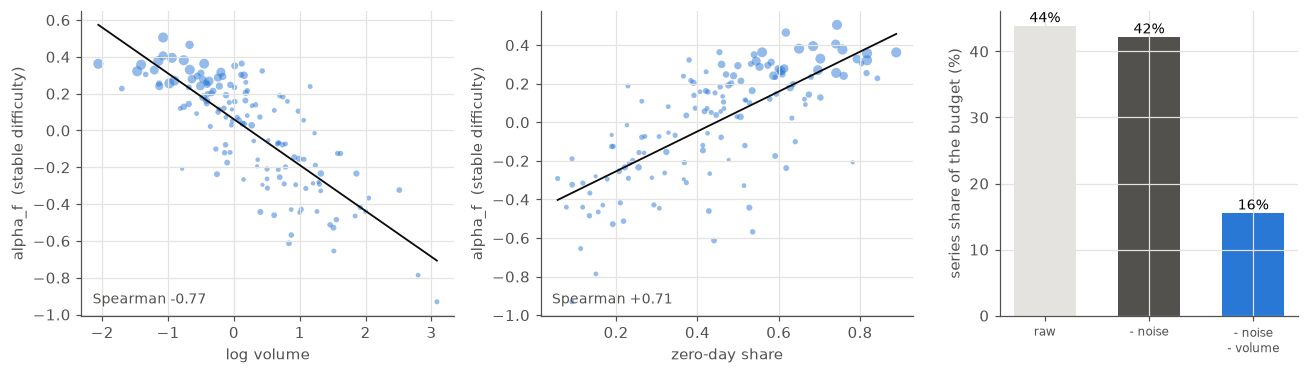

In [19]:
def plot_alpha_vs(covariates, alpha, noise):
    fig, axes = plt.subplots(1, len(covariates) + 1, figsize=(12, 3.5),
                             gridspec_kw={"width_ratios": [1] * len(covariates) + [0.8]})
    for ax, (label, values) in zip(axes, covariates.items()):
        # Size by precision: a big dot is a series whose alpha is well measured. The eye
        # should not weigh a noisy low-volume point like a well-measured one.
        weight = 1 / np.maximum(noise, np.percentile(noise, 5))
        ax.scatter(values, alpha, s=4 + 40 * weight / weight.max(),
                   color=MAIN_COLOR, alpha=0.5, linewidths=0)
        slope, intercept = np.polyfit(values, alpha, 1)
        grid = np.linspace(values.min(), values.max(), 50)
        ax.plot(grid, slope * grid + intercept, color=TEXT_COLOR, linewidth=1.2)
        ax.set_xlabel(label)
        ax.set_ylabel("alpha_f  (stable difficulty)")
        ax.text(0.03, 0.04, f"Spearman {explained['per_covariate'][label]['spearman']:+.2f}",
                transform=ax.transAxes, color=MUTED_TEXT_COLOR, fontsize=9)

    ax = axes[-1]
    labels = ["raw", "- noise", "- noise\n- volume"]
    values = [explained["share_raw"], explained["share_corrected"],
              explained["all_covariates"]["share_corrected"]]
    ax.bar(range(3), [100 * v for v in values],
           color=[GRID_COLOR, MUTED_TEXT_COLOR, MAIN_COLOR], width=0.6)
    for position, value in enumerate(values):
        ax.text(position, 100 * value, f"{100 * value:.0f}%", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(range(3))
    ax.set_xticklabels(labels, fontsize=8)
    ax.set_ylabel("series share of the budget (%)")
    fig.tight_layout()
    return fig

plot_alpha_vs({"log volume": log_volume, "zero-day share": zero_share},
              result.alpha, explained["series_noise"])
plt.show()

**How to read the last bar.** It is the share of the whole error budget that is still
attributable to the identity of the item once its own measurement noise and its volume
are both accounted for. That is the quantity a grouping would have to exploit, and it is
the one to carry into notebook 10 — not the raw series share of section 2.

If it has collapsed, the stable part of difficulty was volume, the "grouping" it licenses
is a sort on a number already visible in the history, and there is nothing a clustering
could add. If a substantial part survives, then items differ in some way that volume does
not capture, and the next question — do those differences form discrete types, or a
continuum? — is worth the full audit.

## 5b. Does the weekly shape carry any of what volume does not explain?

Section 5 answers what the stable item effect *is*: mostly volume. The part that is left
is the only thing a grouping could earn its keep on, and the next notebook proposes to look
for that grouping in the **weekly shape** -- the share of a week falling on each weekday.

Shape is worth a look because it is a different axis from volume by construction: each week
is normalised to 1 before the weeks are pooled, precisely so that how much an item sells
drops out and only *when* it sells remains. But that is also the reason the link cannot be
assumed. The dominant component of the item effect has been removed from the object on
purpose, so whether anything of the item effect is left *in* that object is an open
empirical question -- and the cheapest one here, because it decides whether a clustering of
the shape space is worth building at all.

The test: regress `alpha_f` on the nuisance block (volume, sparsity, and the per-series
noise level from section 5, which also settles the control question by putting it in the
model), then add the shape coordinates and ask what they add.

Three things make that readable rather than merely computed:

- **Shape is measured on history before the first origin**, like the covariates of
  section 5. A profile computed over the scored windows would be partly measured on what
  it is being asked to predict.
- **Six extra regressors explain variance by construction.** The adjustment inside
  `_explained_variance` removes that in expectation; a **permutation test** gives the
  distribution. The shuffle is **stratified by volume**, so the null keeps whatever
  relationship shape has with volume and destroys only its link to difficulty. Permuting
  freely would break the shape-volume relationship too, make the null easier to beat, and
  bias the test toward finding an effect.
- **Shape is itself measured with error**, and error in a *predictor* attenuates what it
  explains toward zero -- the mirror image of the attenuation in section 3b. So the
  increment is reported both as measured and divided by the shape's own reliability, as an
  approximate upper bound on what a perfectly measured shape could contribute.

In [20]:
from m5_chronos2.persistence import select_series, shape_explains_alpha
from m5_chronos2.shapes import (
    shape_matrix, split_half_reliability, weekly_share_array, weekly_shapes)

SHAPE_MIN_WEEKS = 26                 # as in notebook 10, so the two are comparable
shape_last_day = ORIGINS[0]          # strictly before the panel starts

# The panel's membership rule and a shape's are different rules: a series joins the panel
# with 56 on-sale days before the first origin, a shape needs SHAPE_MIN_WEEKS complete
# weeks. An item that launched shortly before the panel satisfies the first and not the
# second, so the population this test can speak about is smaller than the panel -- and the
# difference is counted here rather than assumed away.
shape_table = weekly_shapes(sales, last_day=shape_last_day, min_weeks=SHAPE_MIN_WEEKS)
position = pl.DataFrame({"id": panel.ids}).join(
    shape_table.with_row_index("row").select("id", "row"), on="id", how="left")
has_shape = position["row"].is_not_null().to_numpy()

print(f"shape measured on history to {shape_last_day}, "
      f"at least {SHAPE_MIN_WEEKS} complete weeks")
print(f"  panel series with a shape: {has_shape.sum()} of {len(panel.ids)}"
      f"   ({(~has_shape).sum()} dropped)")
if (~has_shape).all():
    raise ValueError("no panel series has a shape this early: lower SHAPE_MIN_WEEKS")

# Are the dropped series a systematic slice? They will be the younger items, so say so
# with numbers instead of hoping otherwise.
if (~has_shape).any():
    volume_units = np.exp(log_volume)
    print(f"  kept:    median {np.median(volume_units[has_shape]):.2f} units/day, "
          f"median alpha {np.median(result.alpha[has_shape]):+.2f}")
    print(f"  dropped: median {np.median(volume_units[~has_shape]):.2f} units/day, "
          f"median alpha {np.median(result.alpha[~has_shape]):+.2f}")

# A sub-panel, re-decomposed: mu, the origin effects and the budget all belong to the
# series the question is asked about.
sub = select_series(panel, has_shape)
sub_result = decompose(sub)
assert sub.shape[0] >= 80, (
    "fewer than 80 series carry both a panel row and a shape -- too thin to carry a "
    "conclusion. Lower SHAPE_MIN_WEEKS and report the reliability that costs.")

shape_sub = shape_matrix(shape_table)[position.filter(pl.col("row").is_not_null())["row"].to_numpy()]
assert shape_sub.shape[0] == sub.shape[0]

# Reliability of that profile on exactly those series, for the attenuation bound.
share_ids, share_blocks, _ = weekly_share_array(sales, last_day=shape_last_day)
block_of = dict(zip(share_ids, share_blocks))
shape_reliability = split_half_reliability([block_of[i] for i in sub.ids],
                                           n_draws=12, seed=SEED)

nuisance = {
    "log volume": log_volume[has_shape],
    "zero-day share": zero_share[has_shape],
    "log noise": np.log(np.maximum(series_noise(sub), 1e-12)),
}
shape_vs_alpha = shape_explains_alpha(
    sub, sub_result, shape_sub, nuisance,
    shape_reliability=shape_reliability, strata_from="log volume",
    n_permutations=1000, seed=SEED,
)

print(f"\nsplit-half reliability of the shape on these {sub.shape[0]} series: "
      f"{shape_reliability:.3f}")
print(f"item share of the sub-panel's budget: "
      f"{100 * shape_vs_alpha['share_baseline']:.1f}% after the nuisance block"
      f"  ->  {100 * shape_vs_alpha['share_after_shape']:.1f}% after shape")
print(f"shape adds {100 * shape_vs_alpha['increment']:.1f}% of the stable alpha variance"
      f"   (null median {100 * shape_vs_alpha['null_median']:.1f}%, "
      f"95th percentile {100 * shape_vs_alpha['null_p95']:.1f}%)")
print(f"  p = {shape_vs_alpha['p_value']:.4f}  "
      f"(floor {shape_vs_alpha['p_value_floor']:.4f} with "
      f"{shape_vs_alpha['n_permutations']} permutations in "
      f"{shape_vs_alpha['n_strata']} volume strata; "
      f"beat every null: {shape_vs_alpha['beat_all_nulls']})")
if shape_vs_alpha["increment_disattenuated"] is not None:
    print(f"  upper bound if shape were measured perfectly: "
          f"{100 * min(shape_vs_alpha['increment_disattenuated'], 1.0):.1f}%")

shape measured on history to 2015-10-18, at least 26 complete weeks
  panel series with a shape: 135 of 138   (3 dropped)
  kept:    median 1.19 units/day, median alpha +0.07
  dropped: median 0.71 units/day, median alpha +0.20

split-half reliability of the shape on these 135 series: 0.437
item share of the sub-panel's budget: 14.5% after the nuisance block  ->  14.3% after shape
shape adds 0.7% of the stable alpha variance   (null median 0.0%, 95th percentile 1.5%)
  p = 0.1528  (floor 0.0010 with 1000 permutations in 10 volume strata; beat every null: False)
  upper bound if shape were measured perfectly: 1.5%


In [21]:
shape_panel = shape_sub

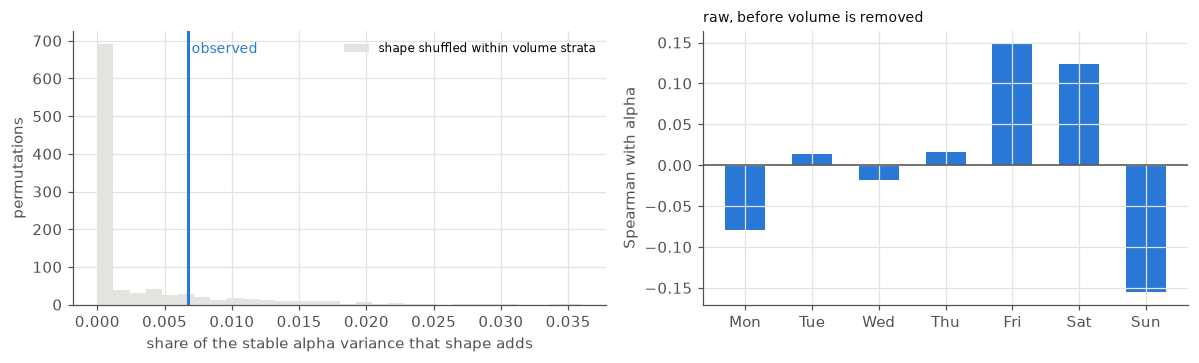

In [22]:
def plot_shape_vs_alpha(stats, alpha, shapes):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4),
                             gridspec_kw={"width_ratios": [1.1, 1]})

    ax = axes[0]
    ax.hist(stats["null_increments"], bins=30, color=GRID_COLOR,
            label="shape shuffled within volume strata")
    ax.axvline(stats["increment"], color=MAIN_COLOR, linewidth=2)
    ax.text(stats["increment"], ax.get_ylim()[1] * 0.92, " observed ",
            ha="left", color=MAIN_COLOR, fontsize=9)
    ax.set_xlabel("share of the stable alpha variance that shape adds")
    ax.set_ylabel("permutations")
    ax.legend(fontsize=8, loc="upper right")

    # Which weekday, if any, tracks difficulty. Descriptive: the test above is joint.
    ax = axes[1]
    ax.bar(range(len(stats["spearman_per_weekday"])), stats["spearman_per_weekday"],
           color=MAIN_COLOR, width=0.6)
    ax.axhline(0, color=MUTED_TEXT_COLOR, linewidth=1)
    ax.set_xticks(range(7))
    ax.set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
    ax.set_ylabel("Spearman with alpha")
    ax.set_title("raw, before volume is removed", loc="left", fontsize=9)
    fig.tight_layout()
    return fig

plot_shape_vs_alpha(shape_vs_alpha, result.alpha, shape_panel)
plt.show()

**How to read this.** The question is deliberately one-sided. A clear increment above
the permutation null means the weekly shape carries difficulty that volume does not, and
the clustering question in notebook 10 is about something real: repairing that audit is
then worth the work, because the types it looks for would organise a quantity that matters.

An increment indistinguishable from the null means the opposite, and it is the more useful
negative result in this study, because it is bounded rather than open-ended. It would say
that the 15.6% of the budget that volume and sparsity do not explain is **not** visible in
the weekly shape, so no verdict about types in the shape space -- however well measured, and
whatever the null envelope eventually says -- can reach it. The grouping question would then
be alive but pointed elsewhere: burstiness, lifecycle, promotion response, price behaviour.

Either way the shape space keeps its place in the argument. It is the one candidate axis
that has been constructed, measured and now tested, and the test is cheap enough that it
should come before the repairs notebook 10 needs rather than after them.

Two limits that no amount of permutation fixes. The regression is linear in the shape
coordinates, so a difficulty that depends on shape *non-monotonically* -- hard at both ends
of the weekend axis, say -- would be missed; and the attenuation bound above is the honest
ceiling on how much a better-measured shape could add.

## 6. Verdict

The rule was fixed before the data was looked at; here it is applied, unmodified. Read it
together with section 3b, which gives the two readings their proper weight:

- **As written, the rule returns "partial"**, and it does so on one arm only: the variance
  share clears 35% comfortably (41.7%, CI [35.6, 47.6]), the Spearman does not clear 0.6
  (+0.52).
- **The arm that fails is the attenuated one.** Corrected for the reliability of a 7-day
  cell, the same data puts the consecutive-origin correlation at 0.86 and the six-month
  correlation at 0.78. Both clear 0.6 by a wide margin.
- **The week accounts for 2% of the variance.** There are essentially no weeks that are hard
  for everybody; difficulty has an address, and the address is the item.

So the conclusion this notebook supports is not "partial, weigh it against the complexity"
but **difficulty is a stable property of the item**, measured through a window too short to
show it directly. What that licenses is a question for notebook 10, and it is a real
question rather than a consolation prize.

In [23]:
print(verdict(result, ranks, intervals))

Partial persistence: weigh the gain against the complexity.
  series (bias-adjusted) 41.7% of the variance, median consecutive-origin Spearman +0.52, first vs last +0.41
  stable at all (series + persistent) 45.7%, of which persistent 4.0%


In [24]:
record = {
    "origins": [str(origin) for origin in ORIGINS],
    "n_origins": n_origins,
    "n_series": n_series,
    "segment_days": SEGMENT_DAYS,
    "context_length": CONTEXT,
    "model": "chronos2 vanilla (zero-shot)",
    "selected_on": f"origins counted back from the validation origin {VALIDATION_ORIGIN}",
    "shares": {key: round(value, 4) for key, value in shares.items()},
    "shares_ci": {key: [round(low, 4), round(high, 4)] for key, (low, high) in intervals.items()},
    "spearman_consecutive_median": round(ranks["consecutive_median"], 4),
    "spearman_first_vs_last": round(ranks["first_vs_last"], 4),
    "worst_decile_survival": round(ranks["worst_decile_survival"], 4),
    "worst_decile_random": round(ranks["worst_decile_random"], 4),
    "verdict": verdict(result, ranks, intervals).splitlines()[0],
    # Section 5, so notebook 10 can inherit the question rather than re-derive it.
    "stable_vs_volume": {
        "share_raw": round(explained["share_raw"], 4),
        "share_noise_corrected": round(explained["share_corrected"], 4),
        "share_after_covariates": round(explained["all_covariates"]["share_corrected"], 4),
        "r2_of_alpha": round(explained["all_covariates"]["r2"], 4),
        "spearman": {name: round(stats["spearman"], 4)
                     for name, stats in explained["per_covariate"].items()},
    },
    # Section 5b, so notebook 10 knows whether its object is relevant before auditing it.
    "shape_vs_alpha": {
        "shape_last_day": str(ORIGINS[0]),
        "shape_min_weeks": SHAPE_MIN_WEEKS,
        "n_series_panel": len(panel.ids),
        "n_series_with_shape": int(has_shape.sum()),
        "shape_reliability": round(shape_vs_alpha["shape_reliability"], 4),
        "nuisance": shape_vs_alpha["nuisance"],
        "share_baseline": round(shape_vs_alpha["share_baseline"], 4),
        "share_after_shape": round(shape_vs_alpha["share_after_shape"], 4),
        "increment": round(shape_vs_alpha["increment"], 4),
        "increment_disattenuated": (
            None if shape_vs_alpha["increment_disattenuated"] is None
            else round(shape_vs_alpha["increment_disattenuated"], 4)),
        "null_median": round(shape_vs_alpha["null_median"], 4),
        "null_p95": round(shape_vs_alpha["null_p95"], 4),
        "p_value": round(shape_vs_alpha["p_value"], 4),
        "p_value_floor": round(shape_vs_alpha["p_value_floor"], 4),
        "beat_all_nulls": bool(shape_vs_alpha["beat_all_nulls"]),
        "n_permutations": shape_vs_alpha["n_permutations"],
        "n_strata": shape_vs_alpha["n_strata"],
        "spearman_per_weekday": [round(v, 4) for v in shape_vs_alpha["spearman_per_weekday"]],
    },
}
path = ARTIFACTS_DIR / f"error_persistence_{NAME}.json"
path.write_text(json.dumps(record, indent=2))
print(f"Saved to {path.name}")
record["verdict"]

Saved to error_persistence_n500_seed42.json


'Partial persistence: weigh the gain against the complexity.'

**How much to trust this.** Three limits, in decreasing order of how much they could change the answer.

1. **One model, one horizon segment.** The sweep uses the zero-shot model on days 1–7. A different model, or
   a longer horizon, could in principle have a different difficulty structure — though it would be odd for a
   fine-tune to create stability that the base model does not see.
2. **24 origins span about six months.** A difficulty that drifts on a yearly scale would read as a constant
   series effect here, which is precisely what the $\rho = 0.97$ row of section 0 shows. That bias is in the
   *favourable* direction: it inflates the series share, so a low series share is not an artefact of the
   span.
3. **The panel is balanced**, so it over-represents items that sell steadily enough to be scorable at all 24
   origins. Those are, if anything, the easiest items to group — another bias in the favourable direction.

Both biases push toward finding structure, so a *low* series share could not have been an
artefact of either. They are the wrong way round for the conclusion actually reached: a high
series share is the direction both biases favour, so the 41.7% should be read as an upper
bound on the item effect rather than a point estimate.

4. **The noise correction of section 3b assumes the sampling-noise estimate is right.** It is
   measured from the odd and even days of each window, on the 2,989 of 3,312 cells where both
   halves contain a sale. If that estimate were too large, the correction would be too
   generous. It is the one number in this notebook that the rest of the argument leans on
   hardest, and the agreement between the predicted and observed correlations in section 3b is
   the evidence that it is approximately right.

## Notes

*Your observations here.*